# Algorithmic complexity as a market efficiency measure: data, splits and baseline

This notebook covers steps 2 to 5 of the project workflow for the idea in
[`research/idea_market_complexity_efficiency.md`](../../research/idea_market_complexity_efficiency.md):

1. **Data.** Select a universe of coins, download hourly Binance candles, validate them.
2. **Preprocessing and split.** Turn returns into symbol sequences, decide the preprocessing, create chronological train / dev / test splits, check for leakage.
3. **Baseline.** Define the task, the metrics and the protocol, and score a fixed baseline.
4. **Method fit.** Check on simulated and real data whether compression-based complexity measures can do what the idea asks of them.

The literature review is in [`research/literature/literature_review_market_complexity.md`](../../research/literature/literature_review_market_complexity.md)
and the conclusions are in [`research/market_complexity_writeup.md`](../../research/market_complexity_writeup.md).

Reusable code lives in `src/scripts/binance_data.py` and `src/scripts/complexity.py`, with tests in `tests/`.

**Running time.** The first run downloads about 420 MB of candles and computes the complexity measures for
717 coin-years (about 15 minutes on 8 cores). Both are cached under `data/`, so later runs take about 3 minutes.

In [1]:
import calendar
import json
import sys
import time
import warnings
import zlib
from datetime import date

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from joblib import Parallel, delayed
from scipy import stats

sys.path.append("../scripts")
import binance_data as bd
import complexity as cx

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220, "display.max_columns", 30, "display.float_format", "{:,.4f}".format)

DATA_END = date(2026, 10, 9)                 # fixed so that reruns give the same data
LISTED_BY, ALIVE_UNTIL = (2020, 12), (2022, 12)   # universe rule, see section 1
TRAIN_END = pd.Timestamp("2023-01-01", tz="UTC")  # train: before this day
DEV_END = pd.Timestamp("2025-01-01", tz="UTC")    # dev: 2023 and 2024, test: from 2025
FULL_YEAR_HOURS = 8500                       # a coin-year needs at least this many hourly bars
OUT_DIR = bd.DATA_DIR / "processed" / "market_complexity"
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Chart style: one fixed colour per series, thin lines, quiet grid.
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, VIOLET = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 90, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.6, "xtick.color": MUTED, "ytick.color": MUTED,
    "lines.linewidth": 1.4, "legend.frameon": False, "font.size": 9.5,
})

## 1. Data

**What the idea needs.** Return series for a broad cross-section of coins, long enough for complexity
estimators, plus a measure of each coin's liquidity. No labels.

**Source.** Hourly spot candles from [data.binance.vision](https://data.binance.vision), free and without an
API key. Hourly bars give about 8,760 observations per coin and year. The candles also contain the traded
value, which serves as the liquidity measure. Market capitalization (suggested in the idea, from CoinGecko)
is not used: it needs a separate source with an API key and adds little over traded value for this question.

### 1.1 Choosing the coins

The universe is fixed by a rule that uses listing dates only, not prices, so that it cannot be tuned towards
a result:

1. All spot pairs quoted in USDT that Binance ever published, **including pairs that were later delisted.**
2. Listed by December 2020 and still trading in December 2022, so that every coin has at least two full
   years (2021 and 2022) in the train period.
3. Excluding stablecoins and fiat currencies, leveraged tokens, tokens pegged to another asset, and one
   ticker (LUNA) that was reused for a different asset.

In [2]:
listing_file = bd.DATA_DIR / "binance_spot_1h" / "_listing.json"
if listing_file.exists():
    listing = json.loads(listing_file.read_text())
else:  # about 760 small requests
    import requests
    session = requests.Session()
    listing = {}
    for symbol in bd.list_symbols("USDT", session):
        months = bd.list_months(symbol, "1h", session)
        if months:
            listing[symbol] = [months[0], months[-1], len(months)]
    listing_file.parent.mkdir(parents=True, exist_ok=True)
    listing_file.write_text(json.dumps(listing))

def universe_status(symbol):
    first, last, _ = listing[symbol]
    if tuple(first) > LISTED_BY:
        return "listed after 2020"
    reason = bd.exclusion_reason(symbol)
    if reason:
        return reason
    if tuple(last) < ALIVE_UNTIL:
        return "delisted before the end of 2022"
    return "kept"

status = pd.Series({s: universe_status(s) for s in listing})
SYMBOLS = sorted(status[status == "kept"].index)
print(f"{len(listing)} USDT pairs published, {len(SYMBOLS)} kept")
status.value_counts().to_frame("pairs")

756 USDT pairs published, 166 kept


,pairs
listed after 2020,506
kept,166
leveraged token,48
delisted before the end of 2022,22
stablecoin or fiat,12
ticker reused for a different asset,1
pegged to another asset,1


In [3]:
def month_end(year, month):
    return date(year, month, calendar.monthrange(year, month)[1])

def ensure_downloaded(symbol):
    path = bd.klines_path(symbol, "1h")
    if path.exists():
        return
    first, last, _ = listing[symbol]
    # Delisted pairs end with their last monthly file; live ones run to DATA_END.
    end = DATA_END if tuple(last) >= (DATA_END.year, DATA_END.month - 1) else month_end(*last)
    path.parent.mkdir(parents=True, exist_ok=True)
    bd.download_klines(symbol, "1h", date(first[0], first[1], 1), end).to_parquet(path)

for symbol in SYMBOLS:
    ensure_downloaded(symbol)

last_bar = pd.Timestamp(DATA_END, tz="UTC") + pd.Timedelta(hours=23)
hourly = {s: bd.load_klines(s, "1h").loc[:last_bar] for s in SYMBOLS}
returns = {s: np.log(h["close"]).diff().dropna() for s, h in hourly.items()}
print(f"{len(hourly)} coins, {sum(len(h) for h in hourly.values()):,} hourly bars in total")

166 coins, 8,896,895 hourly bars in total


### 1.2 Validation

In [4]:
def validate(symbol):
    h, r = hourly[symbol], returns[symbol]
    grid = pd.date_range(h.index[0].floor("h"), h.index[-1].floor("h"), freq="h")
    bad = (h["high"] < h["low"]) | (h["close"] > h["high"]) | (h["close"] < h["low"]) | (h[["open", "high", "low", "close"]] <= 0).any(axis=1)
    return {
        "first bar": h.index[0].strftime("%Y-%m-%d"), "last bar": h.index[-1].strftime("%Y-%m-%d"),
        "bars": len(h), "missing hours": len(grid) - h.index.floor("h").nunique(),
        "duplicates": int(h.index.duplicated().sum()), "bad prices": int(bad.sum()), "NaN cells": int(h.isna().sum().sum()),
        "zero returns %": 100 * (r == 0).mean(), "up share of non-zero %": 100 * (r > 0).sum() / (r != 0).sum(),
        "largest |log return|": r.abs().max(),
        "median daily value (USDT)": h["quote_volume"].resample("D").sum().median(),
        "alive at the end": h.index[-1] >= last_bar - pd.Timedelta(days=2),
    }

validation = pd.DataFrame({s: validate(s) for s in SYMBOLS}).T.infer_objects()
print(f"duplicates: {validation['duplicates'].sum()}, bad prices: {validation['bad prices'].sum()}, NaN cells: {validation['NaN cells'].sum()}")
print(f"alive on {DATA_END}: {validation['alive at the end'].sum()} of {len(validation)}")
validation.select_dtypes("number").describe().T[["min", "25%", "50%", "75%", "max"]]

duplicates: 0, bad prices: 0, NaN cells: 0
alive on 2026-10-09: 104 of 166


,min,25%,50%,75%,max
bars,"22,132.0000","47,296.5000","53,528.0000","61,502.5000","80,053.0000"
missing hours,14.0000,19.0000,30.0000,52.7500,"7,497.0000"
duplicates,0.0000,0.0000,0.0000,0.0000,0.0000
bad prices,0.0000,0.0000,0.0000,0.0000,0.0000
NaN cells,0.0000,0.0000,0.0000,0.0000,0.0000
zero returns %,0.0362,2.2498,3.4377,4.6161,10.5612
up share of non-zero %,48.3701,49.6420,50.0418,50.3569,51.8013
largest |log return|,0.2009,0.3156,0.4053,0.5436,6.8859
median daily value (USDT),"455,498.2394","1,093,122.4398","2,182,791.9369","6,249,820.8529","1,195,648,323.7685"


In [5]:
print("Coins with the most missing hours:")
display(validation.sort_values("missing hours").tail(4)[["first bar", "last bar", "bars", "missing hours"]])
print("Coins with the largest single hourly move:")
display(validation.sort_values("largest |log return|").tail(5)[["largest |log return|"]])
print("Coins with the most zero returns:")
display(validation.sort_values("zero returns %").tail(4)[["zero returns %", "median daily value (USDT)"]])

Coins with the most missing hours:


,first bar,last bar,bars,missing hours
STRAXUSDT,2020-11-18,2026-10-09,51429,216
KEYUSDT,2019-08-27,2024-12-10,45655,712
CVCUSDT,2019-08-27,2026-10-09,58685,3735
FTTUSDT,2019-12-20,2026-10-09,52164,7497


Coins with the largest single hourly move:


,largest |log return|
VTHOUSDT,1.3775
STRAXUSDT,2.2268
DREPUSDT,4.6488
SUNUSDT,6.8385
COCOSUSDT,6.8859


Coins with the most zero returns:


,zero returns %,median daily value (USDT)
SUNUSDT,8.6902,"1,335,640.8938"
JUVUSDT,8.8725,"938,572.0790"
LSKUSDT,8.8798,"674,167.7508"
XVSUSDT,10.5612,"1,817,022.1990"


**Findings.**

- **No duplicates, impossible prices or NaNs** in any of the 166 files.
- **Missing hours are rare** (median 30 per coin, mostly the exchange-wide outages) with two exceptions:
  FTT (about 7,500 hours) and CVC (about 3,700) have gaps of several months in the published data.
- **Four coins have an hourly log return above 2**, up to 6.9, a factor of 1,000. Moves of that size are
  consistent with redenominations (a token swapped at a fixed ratio), not market moves. They affect one
  observation each. Since the
  analysis uses only the sign of each return, they are harmless here, but they would wreck any analysis of
  return sizes.
- **Zero returns are common.** In a median coin 3.4% of hourly returns are exactly zero, up to 10.6%. A zero
  return means the price did not move by even one tick in an hour: a sign of a coarse price grid or of thin
  trading. This is the main preprocessing issue, see section 2.
- **Ups and downs are balanced:** the share of up moves among non-zero returns is between 48.4% and 51.8%.
- **Liquidity spans three orders of magnitude:** the median daily traded value ranges from 0.5 million to
  1.2 billion USDT. That spread is what the liquidity hypothesis needs.
- **Survivorship.** 104 of the 166 coins are still trading at the end of the data. The other 62 stopped
  trading between 2023 and 2026. They are kept for as long as they traded.

## 2. From returns to symbols, and coin-years

Complexity measures work on sequences over a small alphabet. Following the literature, the main coding is
**binary: 1 for an up move, 0 for a down move.** It has two advantages: it is not affected by volatility
(whose clustering would otherwise show up as "compressibility"), and it makes an efficient market easy to
state: a sequence of fair coin flips, with 1 bit of entropy per symbol.

**Zero returns** have no direction. They are **dropped**, so the sequence becomes a little shorter. Section
5.4 shows what happens if they are kept as a third symbol.

**The unit of analysis is the coin-year**: one coin in one calendar year, about 8,760 hourly symbols. Using
the same window for all coins means every measure refers to the same market period and the same sample size.
A coin-year is used if it has at least 8,500 hourly bars.

In [6]:
rows = []
for s in SYMBOLS:
    h, r = hourly[s], returns[s]
    for year, g in r.groupby(r.index.year):
        bars = h[h.index.year == year]
        rows.append({
            "symbol": s, "year": int(year), "hours": len(g),
            "zero_share": float((g == 0).mean()),
            "dollar_volume": float(bars["quote_volume"].resample("D").sum().median()),
            "volatility": float(g.std()),
        })
coin_years = pd.DataFrame(rows)
coin_years["full"] = coin_years["hours"] >= FULL_YEAR_HOURS
coin_years["split"] = np.select([coin_years["year"] <= 2022, coin_years["year"] <= 2024], ["train", "dev"], "test")

by_year = coin_years.groupby("year").agg(
    split=("split", "first"), coins=("symbol", "count"), full_years=("full", "sum"),
    median_hours=("hours", "median"), median_zero_share=("zero_share", "median"),
    max_zero_share=("zero_share", "max"), median_daily_value=("dollar_volume", "median"))
by_year

,split,coins,full_years,median_hours,median_zero_share,max_zero_share,median_daily_value
year,,,,,,,
2017,train,5,0,"1,340.0000",0.0067,0.0199,"6,236,005.7542"
2018,train,17,5,"5,198.0000",0.0060,0.0573,"11,734,862.3594"
2019,train,74,17,"5,212.0000",0.0253,0.1549,"383,408.9492"
2020,train,166,75,"7,474.0000",0.0130,0.1596,"1,463,999.9183"
2021,train,166,166,"8,747.0000",0.0059,0.0238,"12,487,109.7534"
2022,train,166,164,"8,760.0000",0.0332,0.1840,"3,004,918.5709"
2023,dev,164,152,"8,759.0000",0.0443,0.2050,"1,979,928.3684"
2024,dev,155,138,"8,784.0000",0.0222,0.0886,"2,526,653.3571"
2025,test,135,119,"8,760.0000",0.0313,0.1624,"1,562,849.9790"


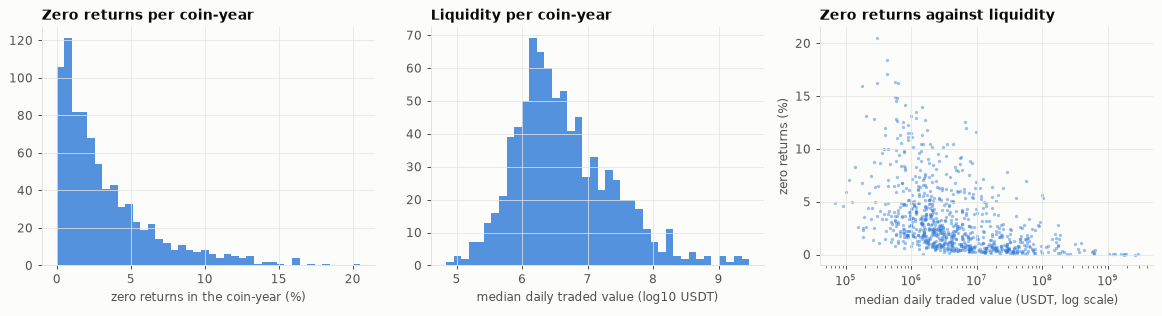

full coin-years: 836; zero share above 10%: 46; Spearman(zero share, traded value) = -0.56


In [7]:
full = coin_years[coin_years["full"]]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
axes[0].hist(100 * full["zero_share"], bins=40, color=BLUE, alpha=0.8)
axes[0].set_xlabel("zero returns in the coin-year (%)"); axes[0].set_title("Zero returns per coin-year")
axes[1].hist(np.log10(full["dollar_volume"]), bins=40, color=BLUE, alpha=0.8)
axes[1].set_xlabel("median daily traded value (log10 USDT)"); axes[1].set_title("Liquidity per coin-year")
axes[2].scatter(full["dollar_volume"], 100 * full["zero_share"], s=7, color=BLUE, alpha=0.45, linewidths=0)
axes[2].set_xscale("log"); axes[2].set_xlabel("median daily traded value (USDT, log scale)"); axes[2].set_ylabel("zero returns (%)")
axes[2].set_title("Zero returns against liquidity")
fig.tight_layout(); plt.show()
rho = stats.spearmanr(full["zero_share"], full["dollar_volume"])[0]
print(f"full coin-years: {len(full)}; zero share above 10%: {(full['zero_share'] > 0.10).sum()}; Spearman(zero share, traded value) = {rho:+.2f}")

**Sizes.** There are 836 full coin-years, each with about 8,700 hourly symbols: 427 in train (2018 to 2022),
290 in dev (2023 and 2024) and 119 in test (2025). The partial year 2026 (about 6,770 hours for 119 coins)
is not a full coin-year; it is used only in the prediction test of section 4, which does not need equal
windows. Train is dominated by 2021 and 2022, when all 166 coins traded. Only 5 coins have a full 2018
and 17 a full 2019, so statements about those years rest on few, large coins.

**Zero returns vary a lot across coin-years** (from almost none to 20%; 46 coin-years exceed 10%) and are
more common in less liquid coins (rank correlation with traded value -0.56). They reflect how coarse the
price grid is relative to the price, and how thinly the coin trades.

### 2.1 Feature set and labels

| | Choice | Why |
| --- | --- | --- |
| **Observation** | The sequence of hourly up / down symbols of a coin | What the complexity measures act on. |
| **Features (per coin-year)** | Complexity measures of the sequence: conditional entropies of order 1 to 8, compressed size under zlib, bz2 and lzma, Lempel-Ziv complexity. Each is reported as a **deficit**: how far it falls below the same measure on shuffled copies. | The deficit is the "inefficiency" of the coin-year, in bits per symbol, free of the estimator's own bias. |
| **Covariates** | Median daily traded value (liquidity), share of zero returns (price grid), volatility, year | To test what inefficiency is related to. |
| **Labels** | **None for the measure itself.** For the out-of-sample check, the label is the next symbol: will the next hour be up or down? | An inefficiency measure makes a testable claim: if the sequence is compressible, its next symbol is predictable better than chance. That gives a supervised task with free labels. |

## 3. Preprocessing and split

### 3.1 Preprocessing decisions

| Issue found in the data | Decision |
| --- | --- |
| Prices are non-stationary | Use log returns, and of those only the sign. |
| Volatility clusters and has intraday patterns | The binary sign coding is unaffected by any positive rescaling of returns, so no volatility filtering is needed. Codings with more symbols would need it (Calcagnile et al., 2016). |
| Zero returns (median 3.4% of hours) | Dropped from the binary sequence. Coin-years with many zeros are flagged through the `zero_share` covariate. |
| Redenominations (hourly returns of a factor of 1,000) | No action needed for signs: one symbol each. |
| Suspended coins and partial years | Coin-years with fewer than 8,500 hourly bars are excluded from the coin-year analysis. |
| Estimators are biased on finite sequences | Every measure is compared with shuffled copies of the same sequence (same length, same symbol frequencies). |
| Delisted coins | Kept while they traded. Dev and test contain fewer coins than train. |

In [8]:
def split_of(index):
    return np.select([index < TRAIN_END, index < DEV_END], ["train", "dev"], "test")

# Hourly returns of all coins with their split, saved for later experiments (data/ is ignored by git).
frames = []
for s in SYMBOLS:
    r = returns[s]
    frames.append(pd.DataFrame({"symbol": s, "time": r.index, "ret": r.to_numpy(np.float32), "split": split_of(r.index)}))
panel = pd.concat(frames, ignore_index=True).astype({"symbol": "category", "split": "category"})
panel.to_parquet(OUT_DIR / "hourly_returns.parquet")
coin_years.to_parquet(OUT_DIR / "coin_years.parquet")

split_table = panel.groupby("split", observed=True).agg(
    first=("time", "min"), last=("time", "max"), coins=("symbol", "nunique"), hourly_returns=("ret", "size")
).loc[["train", "dev", "test"]]
split_table["full coin-years"] = full.groupby("split").size()
split_table

,first,last,coins,hourly_returns,full coin-years
split,,,,,
train,2017-08-17 05:00:00+00:00,2022-12-31 23:00:00+00:00,166,4367090,427
dev,2023-01-01 00:00:00+00:00,2024-12-31 23:00:00+00:00,164,2685591,290
test,2025-01-01 00:00:00+00:00,2026-10-09 23:00:00+00:00,135,1844048,119


### 3.2 The split

**By date:** train is everything before 2023, dev is 2023 and 2024, test runs from 2025 to 2026-10-09.
The same dates apply to every coin.

Since the complexity measures have no parameters to fit, the split plays a different role than in a
prediction project:

- **Train** is where the measurement is designed: coding, estimators, window length, which covariates matter.
- **Dev** checks whether what was found on train repeats in a later period.
- **Test** is kept for one final confirmation. In this notebook only the fixed baseline is run on it.
- For the **prediction check**, the split is used in the usual way: fit on train, score on dev and test.

### 3.3 Leakage checklist

| Risk | How it is handled |
| --- | --- |
| Universe chosen with knowledge of the results | The rule uses listing dates only and was fixed before any measure was computed. Coins delisted after 2022 are included. |
| Survivorship | Requiring a coin to be alive at the end of 2022 looks only at the train period. Later delistings shrink dev and test, they do not remove coins from train. Still, dev and test results describe survivors. |
| Predictor fitted on data it is scored on | Markov models are fitted on train only and scored on dev and test without refitting. |
| Choices tuned on test | Coding, window length and estimator settings were fixed on train. The complexity measures are not computed on test here. |
| Shuffling across a window boundary | Each coin-year is shuffled within itself. |
| Dependence between coins | Coins move together, so 166 coins are not 166 independent observations. Cross-sectional statistics are reported per year, and significance is not taken from pooled counts. |
| Overlapping windows | Coin-years do not overlap. (Sliding windows, as used by Giglio et al., would make the windows dependent.) |

## 4. Baseline

### 4.1 Task, metrics and protocol

**Task.** Given the past signs of a coin's hourly returns, give a probability for the next sign. This is the
predictive form of the efficiency question: in an efficient market the best forecast is 50 / 50 whatever the
past.

**Metrics.**

| Metric | Definition | Why |
| --- | --- | --- |
| **Code length** (main) | mean of $-\log_2 P(\text{symbol} \mid \text{past})$, in bits per symbol, lower is better | This is the out-of-sample compression rate of the sequence under the model, so it measures exactly what the idea is about. An efficient market gives 1 bit. The saving relative to 1 bit is the inefficiency actually captured. |
| **Accuracy** | share of signs predicted correctly | Easy to read. 50% for an efficient market. |
| **Gross return per trade** | mean return of holding the predicted direction for one hour, in basis points | Tells whether a statistical inefficiency is economically relevant, by comparison with trading costs. |

**Protocol.** Fit on train, score on dev and on test, no refitting. A coin is scored on a period if it has
at least 90% of that period's hours. Results are reported as the distribution over coins.

**Baselines.**

| Model | What it is |
| --- | --- |
| Memoryless (order 0) | The efficient-market reference: predicts with the train frequency of ups, ignoring the past. |
| **Markov order 1 (the fixed baseline)** | Uses only the previous sign. It measures the same dependence as the classical lag-1 autocorrelation test of efficiency, expressed in bits. Two parameters per coin. |

A complexity measure earns its place only if it finds structure that this one-step model misses.

In [9]:
def period_symbols(symbol, step_hours=1):
    # Sign symbols of one coin in each split, at a bar size of `step_hours`.
    close = hourly[symbol]["close"]
    if step_hours > 1:
        close = close.resample(f"{step_hours}h").last().dropna()
    r = np.log(close).diff().dropna()
    parts = {name: r[split_of(r.index) == name] for name in ["train", "dev", "test"]}
    expected = {"dev": (DEV_END - TRAIN_END) / pd.Timedelta(hours=step_hours),
                "test": (last_bar - DEV_END) / pd.Timedelta(hours=step_hours)}
    return parts, expected

def score_coin(symbol, step_hours=1, orders=(0, 1, 2, 3, 5, 8), periods=("dev",)):
    parts, expected = period_symbols(symbol, step_hours)
    train = cx.sign_symbols(parts["train"].to_numpy())
    rows = []
    for period in periods:
        r = parts[period]
        if len(r) < 0.9 * expected[period]:
            continue
        symbols = cx.sign_symbols(r.to_numpy())
        row = {"symbol": symbol, "period": period, "n_train": len(train), "n": len(symbols),
               "p_repeat_train": float((train[1:] == train[:-1]).mean()),
               "p_repeat": float((symbols[1:] == symbols[:-1]).mean())}
        for order in orders:
            model = cx.markov_fit(train, order)
            score = cx.markov_score(symbols, model)
            row[f"bits_{order}"], row[f"acc_{order}"] = score["bits"], score["accuracy"]
            if order == 1:  # trade the predicted direction for one bar
                moves = r[r != 0].to_numpy()[1:]
                direction = np.where(cx.markov_predictions(symbols, model) == 1, 1.0, -1.0)
                row["gross_bps"] = 1e4 * float(np.mean(direction * moves))
                row["abs_move_bps"] = 1e4 * float(np.mean(np.abs(moves)))
        rows.append(row)
    return rows

baseline = pd.DataFrame([row for s in SYMBOLS for row in score_coin(s, orders=(0, 1), periods=("dev", "test"))])
baseline["bits_saved"] = baseline["bits_0"] - baseline["bits_1"]
baseline["z_accuracy"] = (baseline["acc_1"] - 0.5) / np.sqrt(0.25 / baseline["n"])

def summarize(g):
    return pd.Series({
        "coins": len(g), "median symbols per coin": g["n"].median(),
        "memoryless: bits": g["bits_0"].mean(), "memoryless: accuracy": g["acc_0"].mean(),
        "order 1: bits": g["bits_1"].mean(), "order 1: accuracy": g["acc_1"].mean(),
        "order 1: lowest accuracy": g["acc_1"].min(), "order 1: highest accuracy": g["acc_1"].max(),
        "bits saved (mean)": g["bits_saved"].mean(), "coins with bits saved > 0": (g["bits_saved"] > 0).mean(),
        "coins with accuracy 3 s.e. above 50%": (g["z_accuracy"] > 3).mean(),
        "share of reversal coins (P(repeat) < 0.5 on train)": (g["p_repeat_train"] < 0.5).mean(),
        "gross return per hour (bps, median)": g["gross_bps"].median(),
        "mean absolute hourly move (bps, median)": g["abs_move_bps"].median(),
    })

baseline_summary = baseline.groupby("period").apply(summarize).T[["dev", "test"]]
baseline_summary

period,dev,test
coins,140.0000,106.0000
median symbols per coin,"16,905.5000","14,869.0000"
memoryless: bits,1.0000,1.0001
memoryless: accuracy,0.5040,0.5007
order 1: bits,0.9983,0.9988
order 1: accuracy,0.5242,0.5218
order 1: lowest accuracy,0.5048,0.4924
order 1: highest accuracy,0.5471,0.5541
bits saved (mean),0.0016,0.0013
coins with bits saved > 0,0.9429,0.8302


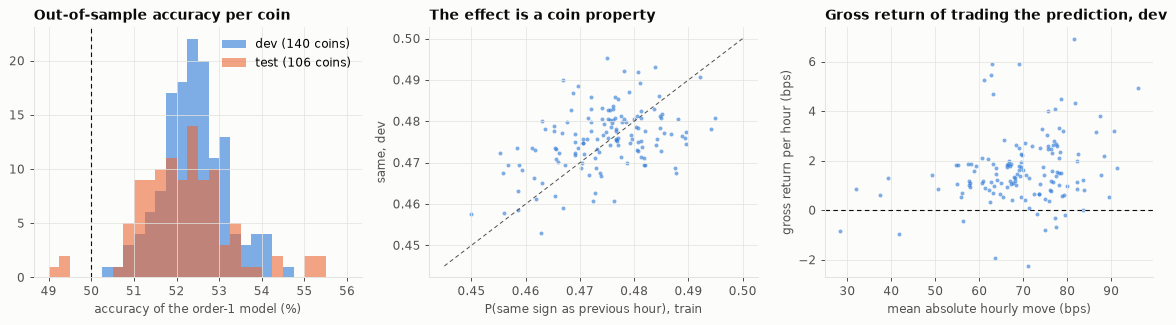

Spearman between train and dev P(repeat): +0.39
BTC: accuracy 53.7% on dev and 51.7% on test; gross 0.87 bps per hour on dev
BTC hourly returns, lag-1 autocorrelation: -0.042; of their signs: -0.072


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.7))
for period, color in [("dev", BLUE), ("test", ORANGE)]:
    g = baseline[baseline["period"] == period]
    axes[0].hist(100 * g["acc_1"], bins=np.arange(49, 56.01, 0.25), color=color, alpha=0.6, label=f"{period} ({len(g)} coins)")
axes[0].axvline(50, color=INK, linewidth=0.9, linestyle=(0, (4, 3)))
axes[0].set_xlabel("accuracy of the order-1 model (%)"); axes[0].set_title("Out-of-sample accuracy per coin"); axes[0].legend()

g = baseline[baseline["period"] == "dev"]
axes[1].scatter(g["p_repeat_train"], g["p_repeat"], s=10, color=BLUE, alpha=0.6, linewidths=0)
low, high = 0.445, 0.50
axes[1].plot([low, high], [low, high], color=MUTED, linewidth=0.8, linestyle=(0, (4, 3)))
axes[1].set_xlabel("P(same sign as previous hour), train"); axes[1].set_ylabel("same, dev")
axes[1].set_title("The effect is a coin property")

axes[2].scatter(g["abs_move_bps"], g["gross_bps"], s=10, color=BLUE, alpha=0.6, linewidths=0)
axes[2].axhline(0, color=INK, linewidth=0.9, linestyle=(0, (4, 3)))
axes[2].set_xlabel("mean absolute hourly move (bps)"); axes[2].set_ylabel("gross return per hour (bps)")
axes[2].set_title("Gross return of trading the prediction, dev")
fig.tight_layout(); plt.show()

rho = stats.spearmanr(g["p_repeat_train"], g["p_repeat"])[0]
btc = baseline[(baseline["symbol"] == "BTCUSDT")].set_index("period")
print(f"Spearman between train and dev P(repeat): {rho:+.2f}")
print(f"BTC: accuracy {100 * btc.loc['dev', 'acc_1']:.1f}% on dev and {100 * btc.loc['test', 'acc_1']:.1f}% on test; gross {btc.loc['dev', 'gross_bps']:.2f} bps per hour on dev")
r_btc = returns["BTCUSDT"]
print(f"BTC hourly returns, lag-1 autocorrelation: {r_btc.autocorr(1):+.3f}; of their signs: {np.sign(r_btc).autocorr(1):+.3f}")

### 4.2 How the baseline performs

- **The memoryless model behaves as an efficient market should:** 1.000 bit per symbol and about 50%
  accuracy.
- **One step of memory beats it, out of sample, for almost every coin.** The order-1 model predicts the next
  sign correctly 52.4% of the time on dev (140 coins) and 52.2% on test (106 coins), and it saves code
  length for 94% of the coins on dev and 83% on test. With about 17,000 symbols per coin, one standard error
  of the accuracy is 0.4 percentage points, so the typical coin is about six standard errors above 50%.
- **The effect is a reversal.** For every coin scored, the probability that an hourly return has the same
  sign as the one before is below one half on train (median 0.475). An up hour is more likely to be followed
  by a down hour. This holds for BTC as well (53.7% accuracy on dev, 51.7% on test; lag-1 autocorrelation of
  its hourly returns -0.04), so it is not a small-coin artifact.
- **It is small.** The saving is about 0.0016 bits per symbol on dev and 0.0013 on test: the sign sequence
  is compressible by about 0.15%.
- **It is not exploitable as it stands.** Trading the predicted direction earns a gross 1.4 basis points per
  hour for the median coin on dev (1.0 on test), against a mean absolute hourly move of about 70 basis
  points. A round trip costs
  far more than that at ordinary exchange fees (0.1% per trade would be 20 basis points). The inefficiency is
  statistically certain and economically negligible, which is consistent with a market that is efficient
  *after costs*.
- **It is a stable property of each coin:** coins with strong reversal on train have strong reversal on dev.

This sets the bar: **a complexity measure has to see at least this known, one-step structure, and to be worth
its cost it has to find more than this.**

## 5. Method fit: can compression-based measures do the job?

### 5.1 Sensitivity on simulated data

Before looking at coins, we ask what each estimator can detect at all in a sequence of one coin-year
(8,760 binary symbols). We simulate sequences in which each symbol repeats the previous one with probability
$p$, from 0.50 (fair coin, an efficient market) downwards (reversal, as in the real data), and count how
often each estimator declares the sequence non-random at the 5% level. Real coins have $p$ between 0.45 and
0.495, with a median of 0.475.

In [11]:
N_SIM = 8760
SIM_ESTIMATORS = ["H1", "H3", "H8", "lz76", "zlib", "bz2", "lzma"]
P_REPEAT = [0.50, 0.49, 0.48, 0.47, 0.45, 0.40, 0.30]

power_file = OUT_DIR / "simulated_power.parquet"
if power_file.exists():
    power = pd.read_parquet(power_file)
else:
    def simulate_values(p, seed, names):
        chain = cx.simulate_markov_chain(N_SIM, p, seed)
        return {name: float(cx.ESTIMATORS[name](chain)) for name in names}
    # Null distribution from 400 fair-coin sequences, then 200 sequences per value of p.
    null = pd.DataFrame(Parallel(n_jobs=-1)(delayed(simulate_values)(0.5, 10_000 + i, SIM_ESTIMATORS) for i in range(400)))
    critical = null.quantile(0.05)
    rows = {}
    for p in P_REPEAT:
        sims = pd.DataFrame(Parallel(n_jobs=-1)(delayed(simulate_values)(p, int(1e6 * p) + i, SIM_ESTIMATORS) for i in range(200)))
        rows[p] = (sims < critical).mean()   # lower value = more regular than a fair coin
    power = pd.DataFrame(rows).T.rename_axis("p_repeat")
    power.to_parquet(power_file)

true_deficit = pd.Series({p: 1 + (p * np.log2(p) + (1 - p) * np.log2(1 - p)) for p in P_REPEAT}, name="true deficit (bits)")
pd.concat([true_deficit, power], axis=1)

,true deficit (bits),H1,H3,H8,lz76,zlib,bz2,lzma
0.5000,0.0000,0.0450,0.0700,0.0850,0.0550,0.0350,0.0300,0.0400
0.4900,0.0003,0.4100,0.2950,0.1300,0.0850,0.0800,0.0950,0.0150
0.4800,0.0012,0.9350,0.8050,0.1850,0.1050,0.0800,0.1450,0.0500
0.4700,0.0026,1.0000,0.9900,0.4150,0.2200,0.1100,0.3300,0.1000
0.4500,0.0072,1.0000,1.0000,0.9600,0.4800,0.2650,0.7600,0.2650
0.4000,0.0290,1.0000,1.0000,1.0000,1.0000,0.9700,1.0000,0.9900
0.3000,0.1187,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000


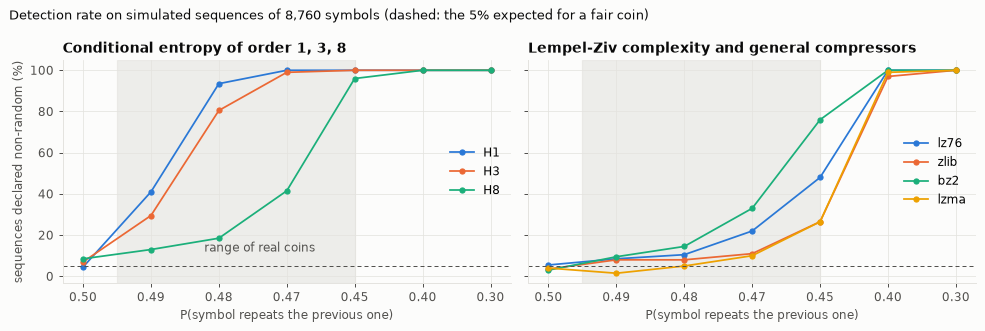

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.7), sharey=True)
x = np.arange(len(P_REPEAT))
for ax, names, title in [(axes[0], ["H1", "H3", "H8"], "Conditional entropy of order 1, 3, 8"),
                         (axes[1], ["lz76", "zlib", "bz2", "lzma"], "Lempel-Ziv complexity and general compressors")]:
    for name, color in zip(names, [BLUE, ORANGE, AQUA, YELLOW]):
        ax.plot(x, 100 * power[name], color=color, marker="o", markersize=4, label=name)
    ax.axhline(5, color=MUTED, linewidth=0.8, linestyle=(0, (4, 3)))
    ax.axvspan(0.5, 4.0, color=GRID, alpha=0.6, zorder=0)
    ax.set_xticks(x); ax.set_xticklabels([f"{p:.2f}" for p in P_REPEAT])
    ax.set_xlabel("P(symbol repeats the previous one)"); ax.set_title(title); ax.legend(loc="center right")
axes[0].set_ylabel("sequences declared non-random (%)")
axes[0].annotate("range of real coins", (2.6, 12), ha="center", color=MUTED)
fig.suptitle(f"Detection rate on simulated sequences of {N_SIM:,} symbols (dashed: the 5% expected for a fair coin)", x=0.01, ha="left", fontsize=10.5, color=INK)
fig.tight_layout(); plt.show()

**This is the central result on method fit.**

- The **order-1 conditional entropy** detects a repeat probability of 0.48 in most sequences and of 0.47
  in practically all of them (exact rates in the table above).
- **Lempel-Ziv complexity, zlib and lzma detect little in the range of real coins.** They respond reliably
  only at a repeat probability of about 0.40: a market in which the next sign could be called correctly 60%
  of the time. bz2 is the most sensitive of the compressors to reversal (76% at 0.45), but still far behind
  the order-1 entropy.
- The reason is the size of the effect against the noise of the estimator. At 0.48 the sequence is
  compressible by 0.1%, or about 10 bits in a whole year of hourly data. A general compressor's output
  varies by far more than that between two random sequences of the same length.
- High-order entropies lose sensitivity too (order 8 needs about 0.45), because the number of contexts
  grows and each is seen rarely.

**So with one year of hourly data, general-purpose compressors cannot see inefficiencies of the size that
exists in these markets.** A finding of "high complexity" from them says little: they would mostly report
the same for a market that is predictable 53% of the time.

### 5.2 The measures on real coin-years

Now the measures on the 717 full coin-years of train and dev. For each coin-year and each estimator we
compute the value on the sequence and on shuffled copies (200 copies, 50 for the slow Lempel-Ziv parsing),
and report the deficit and its significance.

In [13]:
profile_file = OUT_DIR / "coin_year_profiles.parquet"
if profile_file.exists():
    profiles = pd.read_parquet(profile_file)
else:
    def profile_coin_year(row, symbols):
        seed = zlib.crc32(f"{row['symbol']}-{row['year']}".encode())   # reproducible per coin-year
        return {**row, **cx.complexity_profile(symbols, n_surrogates=200, n_slow_surrogates=50, seed=seed)}
    jobs = []
    for row in full[full["split"] != "test"][["symbol", "year", "hours", "zero_share", "dollar_volume", "volatility"]].to_dict("records"):
        r = returns[row["symbol"]]
        jobs.append((row, cx.sign_symbols(r[r.index.year == row["year"]].to_numpy())))
    start = time.time()
    profiles = pd.DataFrame(Parallel(n_jobs=-1, batch_size=4)(delayed(profile_coin_year)(row, s) for row, s in jobs))
    profiles.to_parquet(profile_file)
    print(f"computed {len(profiles)} coin-year profiles in {time.time() - start:.0f}s")

profiles["split"] = np.where(profiles["year"] <= 2022, "train", "dev")
ESTIMATORS = list(cx.ESTIMATORS)

rows = {}
for name in ESTIMATORS:
    row = {}
    for split in ["train", "dev"]:
        g = profiles[profiles["split"] == split]
        row[(split, "median deficit")] = g[f"{name}_deficit"].median()
        row[(split, "median z")] = g[f"{name}_z"].median()
        row[(split, "p < 0.05")] = (g[f"{name}_p_value"] < 0.05).mean()
        row[(split, "non-random after FDR control")] = cx.benjamini_hochberg(g[f"{name}_p_value"].to_numpy()).mean()
    rows[name] = row
detection = pd.DataFrame(rows).T
detection.columns = pd.MultiIndex.from_tuples(detection.columns)
print(f"coin-years: {profiles.groupby('split').size().to_dict()}, median symbols per coin-year: {profiles['n'].median():.0f}")
print(f"Lempel-Ziv index above 1 (the efficiency criterion of Giglio et al.): {100 * (profiles['lz76_value'] > 1).mean():.0f}% of coin-years")
detection

coin-years: {'dev': 290, 'train': 427}, median symbols per coin-year: 8575
Lempel-Ziv index above 1 (the efficiency criterion of Giglio et al.): 100% of coin-years


train                                                           dev                                               
     median deficit median z p < 0.05 non-random after FDR control median deficit median z p < 0.05 non-random after FDR control
H1           0.0016  13.4184   0.9157                       0.9133         0.0016  13.6387   0.9241                       0.9241
H2           0.0024  11.5481   0.9742                       0.9672         0.0019   8.9013   0.9207                       0.9207
H3           0.0026   8.3514   0.9625                       0.9625         0.0021   6.5009   0.9138                       0.9034
H5           0.0029   4.3935   0.8665                       0.8571         0.0022   3.2283   0.7552                       0.7172
H8           0.0029   1.5420   0.4520                       0.3162         0.0025   1.2962   0.3897                       0.1379
zlib         0.0034   0.4802   0.1171                       0.0000         0.0029   0.4002   0.0759                       0.0000
bz2          0.0103   1.7577   0.4941                       0.3162         0.0086   1.4487   0.3897                       0.1448
lzma         0.0036   0.5219   0.1194                       0.0000         0.0045   0.6158   0.0759                       0.0000
lz76         0.0030   0.5703   0.1265                       0.0000         0.0027   0.4707   0.0931                       0.0000

In [14]:
# Reliability: is a coin's deficit in one year related to its deficit the next year?
pairs = [(2020, 2021), (2021, 2022), (2022, 2023), (2023, 2024)]
reliability = {}
for name in ESTIMATORS:
    wide = profiles.pivot(index="symbol", columns="year", values=f"{name}_deficit")
    reliability[name] = {f"{a} to {b}": stats.spearmanr(*wide[[a, b]].dropna().to_numpy().T)[0] for a, b in pairs}
reliability = pd.DataFrame(reliability).T
reliability["mean"] = reliability.mean(axis=1)
print("Rank correlation across coins between a year's deficit and the next year's:")
display(reliability)

print("Rank correlation between estimators (deficits over all coin-years):")
shown = ["H1", "H3", "H8", "lz76", "zlib", "bz2", "lzma"]
profiles[[f"{n}_deficit" for n in shown]].rename(columns=lambda c: c.replace("_deficit", "")).corr(method="spearman").round(2)

Rank correlation across coins between a year's deficit and the next year's:


,2020 to 2021,2021 to 2022,2022 to 2023,2023 to 2024,mean
H1,0.3184,0.3977,0.4282,0.3468,0.3728
H2,0.3364,0.4596,0.4605,0.3808,0.4093
H3,0.2788,0.4119,0.4696,0.3577,0.3795
H5,0.2356,0.3451,0.4338,0.2914,0.3265
H8,0.2132,0.2030,0.1680,0.2343,0.2046
zlib,-0.3092,0.0717,0.0749,0.1406,-0.0055
bz2,0.1687,0.1759,0.1040,0.0049,0.1134
lzma,-0.0007,0.2066,0.0761,0.0919,0.0935
lz76,0.1102,0.2334,0.0934,0.0063,0.1108


Rank correlation between estimators (deficits over all coin-years):


,H1,H3,H8,lz76,zlib,bz2,lzma
H1,1.0000,0.8900,0.5800,0.2000,0.2200,0.5000,0.2600
H3,0.8900,1.0000,0.6600,0.2600,0.2300,0.5300,0.2800
H8,0.5800,0.6600,1.0000,0.3500,0.2900,0.5400,0.3400
lz76,0.2000,0.2600,0.3500,1.0000,0.4700,0.3000,0.2500
zlib,0.2200,0.2300,0.2900,0.4700,1.0000,0.2000,0.3100
bz2,0.5000,0.5300,0.5400,0.3000,0.2000,1.0000,0.2800
lzma,0.2600,0.2800,0.3400,0.2500,0.3100,0.2800,1.0000


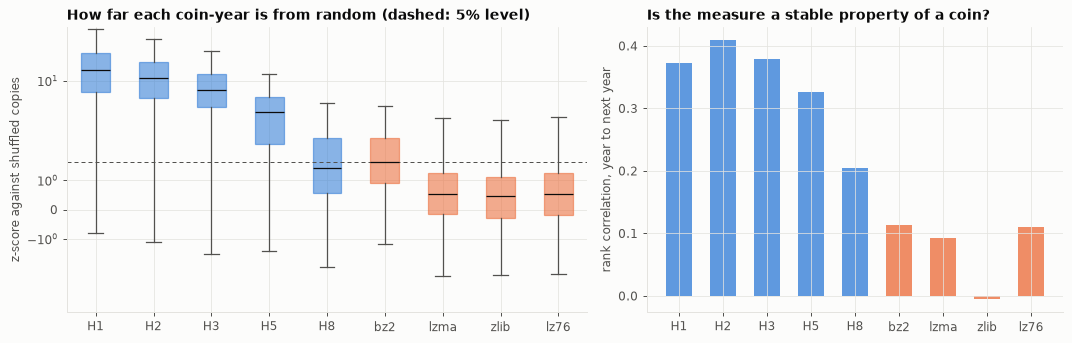

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.9), gridspec_kw={"width_ratios": [1.25, 1]})
order = ["H1", "H2", "H3", "H5", "H8", "bz2", "lzma", "zlib", "lz76"]
colors = [BLUE] * 5 + [ORANGE] * 4
boxes = axes[0].boxplot([profiles[f"{n}_z"] for n in order], tick_labels=order, showfliers=False, patch_artist=True,
                        medianprops={"color": INK}, whiskerprops={"color": MUTED}, capprops={"color": MUTED})
for patch, color in zip(boxes["boxes"], colors):
    patch.set_facecolor(color); patch.set_alpha(0.55); patch.set_edgecolor(color)
axes[0].axhline(1.645, color=MUTED, linewidth=0.8, linestyle=(0, (4, 3)))
axes[0].set_yscale("symlog", linthresh=3); axes[0].set_ylabel("z-score against shuffled copies")
axes[0].set_title("How far each coin-year is from random (dashed: 5% level)")

x = np.arange(len(order))
axes[1].bar(x, reliability.loc[order, "mean"], color=colors, alpha=0.75, width=0.6)
axes[1].set_xticks(x); axes[1].set_xticklabels(order); axes[1].set_ylabel("rank correlation, year to next year")
axes[1].set_title("Is the measure a stable property of a coin?")
fig.tight_layout(); plt.show()

**The real data repeats the simulation.**

- **Low-order entropies find structure almost everywhere.** Orders 1 to 3 declare 90 to 97% of coin-years
  non-random after controlling the false discovery rate, with a typical z-score of 6 to 14. The deficit is
  about 0.002 bits per symbol.
- **Lempel-Ziv complexity, zlib and lzma find it nowhere:** not a single coin-year survives the false
  discovery control, and their typical z-score is about 0.5. The normalized Lempel-Ziv index is above 1 for
  every coin-year, so by the criterion of Giglio et al. (2008) all 717 coin-years would count as efficient.
- **bz2 is in between** (14 to 32% of coin-years), as in the simulation, where it was the compressor most
  sensitive to reversal.
- **Only the entropy measures are stable coin properties.** A coin's entropy deficit in one year is
  correlated about 0.4 with its deficit in the next. For the compressors that correlation is about 0.1 or
  less: their deficits are mostly noise.
- **Orders above 3 add nothing** and lose significance, so the structure present is short-range. Order 2
  is slightly more stable from year to year than order 1.

### 5.3 The hypothesis: are less liquid coins less efficient?

Rank correlation across coins, within each year, between the deficit and a covariate:


2020    2021    2022    2023    2024
traded value H1   -0.2546 -0.0719 -0.1889  0.1402  0.2540
             H3   -0.1131 -0.0566 -0.0392  0.2394  0.3259
             lzma -0.1426 -0.0595 -0.0476 -0.0173 -0.0175
             lz76 -0.1030  0.0321  0.0880  0.0365  0.1098
zero share   H1    0.1839  0.1727  0.1350  0.0701  0.0106
volatility   H1   -0.0460  0.3696  0.1257 -0.0594 -0.1675

coins per year: {2020: 75, 2021: 166, 2022: 164, 2023: 152, 2024: 138}


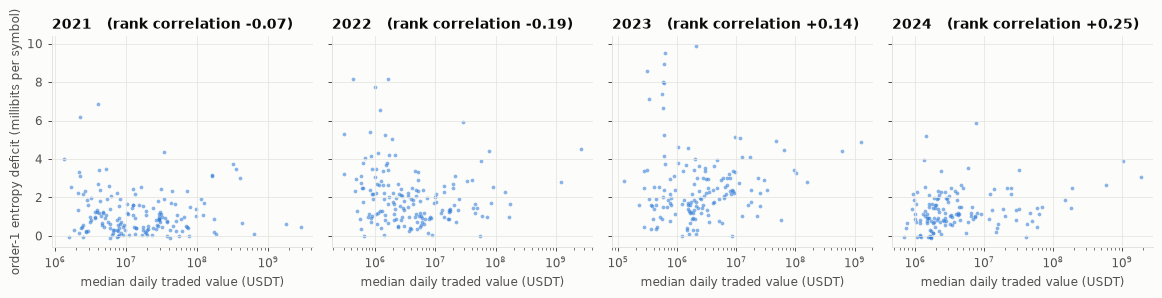

In [16]:
def within_year(measure, covariate):
    return {year: stats.spearmanr(g[measure], g[covariate])[0] for year, g in profiles.groupby("year") if len(g) >= 50}

association = pd.DataFrame({
    ("traded value", "H1"): within_year("H1_deficit", "dollar_volume"),
    ("traded value", "H3"): within_year("H3_deficit", "dollar_volume"),
    ("traded value", "lzma"): within_year("lzma_deficit", "dollar_volume"),
    ("traded value", "lz76"): within_year("lz76_deficit", "dollar_volume"),
    ("zero share", "H1"): within_year("H1_deficit", "zero_share"),
    ("volatility", "H1"): within_year("H1_deficit", "volatility"),
}).T
association["coins"] = ""
print("Rank correlation across coins, within each year, between the deficit and a covariate:")
display(association.drop(columns="coins"))
print("coins per year:", profiles.groupby("year").size().loc[association.columns[:-1]].to_dict())

years = [2021, 2022, 2023, 2024]
fig, axes = plt.subplots(1, 4, figsize=(13, 3.3), sharey=True)
for ax, year in zip(axes, years):
    g = profiles[profiles["year"] == year]
    ax.scatter(g["dollar_volume"], 1000 * g["H1_deficit"], s=9, color=BLUE, alpha=0.55, linewidths=0)
    ax.set_xscale("log"); ax.set_title(f"{year}   (rank correlation {stats.spearmanr(g['H1_deficit'], g['dollar_volume'])[0]:+.2f})")
    ax.set_xlabel("median daily traded value (USDT)")
axes[0].set_ylabel("order-1 entropy deficit (millibits per symbol)")
fig.tight_layout(); plt.show()

In [17]:
# Has the market become more efficient? Median order-1 deficit by year, for all coins and for a fixed set.
veterans = profiles.groupby("symbol")["year"].min()
veterans = veterans[veterans <= 2020].index          # coins with a full 2020 or earlier
trend = pd.DataFrame({
    "all coins": profiles.groupby("year")["H1_deficit"].median(),
    "coins in the sample since 2020": profiles[profiles["symbol"].isin(veterans)].groupby("year")["H1_deficit"].median(),
    "BTC": profiles[profiles["symbol"] == "BTCUSDT"].set_index("year")["H1_deficit"],
}) * 1000
trend["coin-years"] = profiles.groupby("year").size()
print("Order-1 entropy deficit by year, in millibits per symbol:")
trend

Order-1 entropy deficit by year, in millibits per symbol:


,all coins,coins in the sample since 2020,BTC,coin-years
year,,,,
2018,5.2665,5.2665,8.7261,5
2019,4.8912,4.8912,7.8154,17
2020,3.0079,3.0079,6.0718,75
2021,0.8753,0.9068,0.4851,166
2022,1.7456,1.7977,4.5078,164
2023,2.1880,2.2032,4.9093,152
2024,1.1464,1.1561,3.0492,138


**The liquidity hypothesis is not supported in its simple form.**

- In 2020 to 2022 less liquid coins were slightly less efficient (rank correlations of -0.07 to -0.25
  between the deficit and traded value), as the hypothesis says.
- In 2023 and 2024 the sign is the opposite: **more** liquid coins had the larger deficit (+0.14 and +0.25).
- In no year is the relation strong. The scatter plots show a cloud, not a line.
- The relation with the share of zero returns is weak (0.0 to 0.2) and the reversal is present in BTC, whose
  price grid is negligible relative to its price. The effect is therefore not simply a coarse-price-grid
  artifact, although this should be checked properly with bid and ask prices.
- **The clearest pattern is over time, not across coins.** The median deficit was about 5 millibits in 2018
  and 2019, 3 in 2020, and 1 to 2 since 2021. BTC alone fell from 8.7 millibits in 2018 to 3.0 in 2024
  (with a low of 0.5 in 2021). The market has become more efficient, though the early years rest on few
  coins.
- **BTC is not the most efficient coin by this measure.** Its deficit is above the median coin's in every
  year except 2021, which fits the positive relation with liquidity in the later years.
- The compressor-based deficits are unrelated to anything, as expected from noise.

### 5.4 How the coding drives the result

The literature warns that codings with more than two symbols measure volatility and price-grid effects
rather than inefficiency. A quick check: keep zero returns as a third symbol and repeat the order-1 measure.

In [18]:
ternary_file = OUT_DIR / "coin_year_ternary.parquet"
if ternary_file.exists():
    ternary = pd.read_parquet(ternary_file)
else:
    def ternary_coin_year(symbol, year, values):
        result = cx.surrogate_test(cx.ternary_symbols(values), cx.ESTIMATORS["H1"], 100, seed=zlib.crc32(f"{symbol}-{year}".encode()))
        return {"symbol": symbol, "year": year, "ternary_H1_deficit": result["deficit"], "ternary_H1_z": result["z"]}
    jobs = [(row.symbol, row.year, returns[row.symbol][returns[row.symbol].index.year == row.year].to_numpy()) for row in profiles.itertuples()]
    ternary = pd.DataFrame(Parallel(n_jobs=-1, batch_size=16)(delayed(ternary_coin_year)(*job) for job in jobs))
    ternary.to_parquet(ternary_file)

both = profiles.merge(ternary, on=["symbol", "year"])
coding = pd.DataFrame({
    "median deficit (millibits)": [1000 * both["H1_deficit"].median(), 1000 * both["ternary_H1_deficit"].median()],
    "rank correlation with zero share": [stats.spearmanr(both["H1_deficit"], both["zero_share"])[0], stats.spearmanr(both["ternary_H1_deficit"], both["zero_share"])[0]],
    "rank correlation with traded value": [stats.spearmanr(both["H1_deficit"], both["dollar_volume"])[0], stats.spearmanr(both["ternary_H1_deficit"], both["dollar_volume"])[0]],
}, index=["binary (zeros dropped)", "ternary (zeros kept as a symbol)"])
print(f"rank correlation between the two codings' deficits: {stats.spearmanr(both['H1_deficit'], both['ternary_H1_deficit'])[0]:+.2f}")
coding

rank correlation between the two codings' deficits: +0.89


,median deficit (millibits),rank correlation with zero share,rank correlation with traded value
binary (zeros dropped),1.5998,0.2191,-0.1417
ternary (zeros kept as a symbol),1.8856,0.3915,-0.2142


**The coding shifts the answer in the direction the literature warns of, but modestly here.** With zero
returns kept as a symbol, the median deficit is about 18% larger, and it is more strongly related to the
share of zero returns (0.39 against 0.22) and to traded value (-0.21 against -0.14). Part of what the
ternary coding measures is that hours without a price change come in runs, which is a statement about the
price grid and trading activity, not about predictable direction. The two codings still rank coin-years
similarly (rank correlation 0.89). A wider "flat" band or more symbols would let volatility clustering in
as well; that was not tested, and any such coding must first remove these effects, as Calcagnile et al.
(2016) do.

### 5.5 Do longer memories or coarser bars help the predictor?

Last check on what a more complex model could add: Markov models of higher order, and the same task at
4-hour and daily bars, scored on dev only.

In [19]:
ORDERS = (0, 1, 2, 3, 5, 8)
rows = {}
for step, label in [(1, "1 hour"), (4, "4 hours"), (24, "1 day")]:
    scored = pd.DataFrame([row for s in SYMBOLS for row in score_coin(s, step, ORDERS, ("dev",))])
    row = {("", "coins"): len(scored), ("", "train symbols (median)"): scored["n_train"].median(),
           ("", "P(repeat) on train (median)"): scored["p_repeat_train"].median(),
           ("", "P(repeat) on dev (median)"): scored["p_repeat"].median()}
    for order in ORDERS[1:]:
        row[("millibits saved vs. memoryless", f"order {order}")] = 1000 * (scored["bits_0"] - scored[f"bits_{order}"]).mean()
    for order in ORDERS[1:]:
        row[("accuracy %", f"order {order}")] = 100 * scored[f"acc_{order}"].mean()
    rows[label] = row
horizons = pd.DataFrame(rows)
horizons.index = pd.MultiIndex.from_tuples(horizons.index)
horizons

1 hour    4 hours     1 day
                               coins                          140.0000   140.0000  140.0000
                               train symbols (median)      23,419.5000 5,916.5000  989.0000
                               P(repeat) on train (median)      0.4753     0.4720    0.4621
                               P(repeat) on dev (median)        0.4758     0.4758    0.4819
millibits saved vs. memoryless order 1                          1.6397     1.5270   -0.4613
                               order 2                          1.7412     1.4815   -2.1805
                               order 3                          1.8184     1.1146   -3.9743
                               order 5                          1.1686    -1.7982  -20.9975
                               order 8                         -5.7349   -29.5472 -143.8566
accuracy %                     order 1                         52.4173    52.4038   51.8237
                               order 2                         52.2643    52.3326   51.6933
                               order 3                         52.3151    52.1879   51.5724
                               order 5                         52.0941    51.5853   50.9298
                               order 8                         51.2668    50.8100   50.0762

- **Longer memory adds almost nothing at hourly bars.** Order 3 saves 1.8 millibits against 1.6 for order
  1, and from order 5 the models overfit: order 8 is worse than the memoryless model. Accuracy is highest at
  order 1.
- **The reversal is also present at 4-hour bars**, with the same out-of-sample saving. That speaks against
  a bounce between bid and ask prices as the only cause, since a bounce would fade as the bar gets longer.
- **At daily bars nothing can be confirmed out of sample.** With about 1,000 train symbols per coin, the
  order-1 model does not save code length on dev, although its accuracy is 51.8% and the train data shows
  the same tendency. Daily
  data, which most of the earlier literature uses, is too short for this kind of analysis.

## 6. Summary

| Question | Answer |
| --- | --- |
| Is the data usable? | Yes. 166 coins chosen by a fixed rule, delisted ones included, 8.9 million hourly returns, no invalid prices. |
| Is there enough? | For hourly analysis yes: 836 full coin-years of about 8,700 symbols. For daily analysis no. |
| Features and labels? | Per coin-year: complexity deficits against shuffled copies, with liquidity, zero share and volatility as covariates. No labels for the measure; the next sign is the label of the out-of-sample check. |
| Preprocessing? | Binary sign coding with zero returns dropped; full coin-years only; every estimator compared with shuffles. |
| Split? | By date: train before 2023, dev 2023-24, test from 2025. |
| Baseline? | Order-1 Markov model: 52.4% accuracy on dev and 52.2% on test, saving 0.0016 and 0.0013 bits per symbol, positive for 94% and 83% of coins. Not exploitable after costs. |
| Do the proposed methods fit? | **Compression-based measures do not:** at one year of hourly data they cannot detect inefficiencies of the size that exists, and their values are noise. **Entropy-based measures do:** they detect it in over 90% of coin-years and are stable from year to year. |
| Is the hypothesis supported? | Not in its simple form: the relation with liquidity is weak and changes sign. Efficiency has clearly improved over time. |

The full discussion is in [`research/market_complexity_writeup.md`](../../research/market_complexity_writeup.md).